# Lab 06 — Attention Mechanism

IMDb sentiment classification, scaled dot-product attention, self-attention và giới hạn chi phí theo sequence length.

## Thiết lập

In [1]:
from collections import Counter
from pathlib import Path
import random
import re
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

LAB_DIR = Path.cwd().resolve()
if LAB_DIR.name != 'lab06':
    LAB_DIR = LAB_DIR / 'labs' / 'lab06'
REPO_ROOT = LAB_DIR.parents[1]
DATA_DIR = REPO_ROOT / 'labs' / 'lab04' / 'data'
sys.path.insert(0, str(LAB_DIR))
from attention_numpy import scaled_dot_product_attention, self_attention, stable_softmax

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


## 14–15. Scaling và temperature

In [2]:
raw_scores = np.array([[4.0, 2.0, 0.0]])
scaled_scores = raw_scores / np.sqrt(4)
scaling_table = pd.DataFrame([
    {'case': 'without scaling', 'scores': raw_scores.ravel(), 'weights': stable_softmax(raw_scores).ravel()},
    {'case': 'divide by sqrt(dk)=2', 'scores': scaled_scores.ravel(), 'weights': stable_softmax(scaled_scores).ravel()},
])
scaling_table

,case,scores,weights
0,without scaling,"[4.0, 2.0, 0.0]","[0.8668133321973347, 0.11731042782619835, 0.01..."
1,divide by sqrt(dk)=2,"[2.0, 1.0, 0.0]","[0.6652409557748218, 0.24472847105479764, 0.09..."


**Trả lời:** Khi không scaling, attention weight lớn nhất là 0.8668. Sau khi chia scores cho `sqrt(d_k) = 2`, weight lớn nhất giảm còn 0.6652.
Như vậy scaling làm phân phối attention bớt tập trung vào phần tử có score lớn nhất.

In [3]:
temperature_rows = []
temperature_scores = np.array([1.0, 2.0, 3.0])
for temperature in [0.5, 1.0, 2.0]:
    weights = stable_softmax(temperature_scores / temperature)
    entropy = -np.sum(weights * np.log(weights))
    temperature_rows.append({'temperature': temperature, 'max_weight': weights.max(), 'entropy_nats': entropy, 'weights': weights})
temperature_table = pd.DataFrame(temperature_rows)
temperature_table

,temperature,max_weight,entropy_nats,weights
0,0.5,0.866813,0.441057,"[0.015876239976466765, 0.11731042782619838, 0...."
1,1.0,0.665241,0.832396,"[0.09003057317038046, 0.24472847105479764, 0.6..."
2,2.0,0.506480,1.020191,"[0.1863237232258476, 0.3071958857184984, 0.506..."


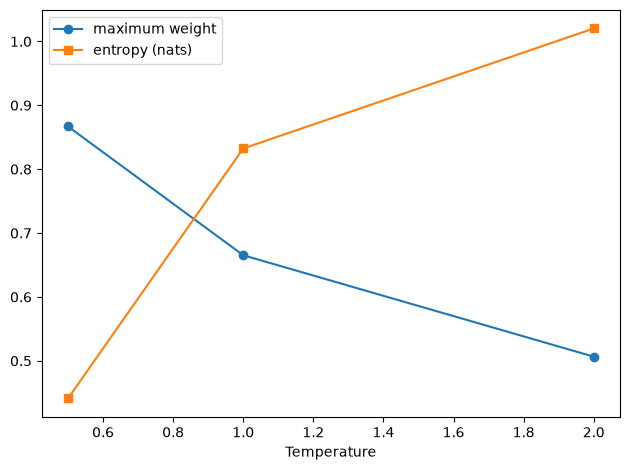

In [4]:
plt.plot(temperature_table['temperature'], temperature_table['max_weight'], marker='o', label='maximum weight')
plt.plot(temperature_table['temperature'], temperature_table['entropy_nats'], marker='s', label='entropy (nats)')
plt.xlabel('Temperature')
plt.legend()
plt.tight_layout()
plt.show()

**Trả lời:** Khi temperature tăng từ 0.5 lên 2.0, max weight giảm từ 0.8668 xuống 0.5065, còn entropy tăng từ 0.4411 lên 1.0202.
Kết quả này cho thấy temperature thấp làm attention tập trung mạnh hơn, còn temperature cao khiến phân phối đều hơn.

## 16. Core implementation

In [5]:
q_core = np.array([[1.0, 0.0]])
k_core = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
v_core = np.array([[1.0, 0.0], [0.0, 2.0], [2.0, 1.0]])
core_scores, core_weights, core_context = scaled_dot_product_attention(q_core, k_core, v_core)
print('scaled scores:', np.round(core_scores, 4))
print('attention weights:', np.round(core_weights, 4))
print('context:', np.round(core_context, 4))

scaled scores: [[0.7071 0.     0.7071]]
attention weights: [[0.4011 0.1978 0.4011]]
context: [[1.2033 0.7967]]


Implementation NumPy trả về scaled scores, attention weights và context. Bài tính tay dùng dot-product score chưa scaling.

## 17. Numerical stability

In [6]:
large_scores = np.array([1000.0, 1001.0, 1002.0])
stable_weights = stable_softmax(large_scores)
pd.DataFrame({'score': large_scores, 'stable_softmax': stable_weights})

,score,stable_softmax
0,1000.0,0.090031
1,1001.0,0.244728
2,1002.0,0.665241


**Trả lời:** Trừ `max(x)` chỉ nhân cả tử và mẫu với cùng một hệ số `exp(-max(x))`, nên softmax không đổi. Việc này tránh overflow khi tính exponential.

## 18. Experiment 1 — Attention distribution

Dùng một bộ vector giả lập có bốn đặc trưng: sentiment, polarity phụ, chủ đề phim và contrast. Query sentiment được chọn là `[1, 0, 0, 0]`. Các vector này chỉ phục vụ quan sát phép tính, không phải embedding đã học.

In [7]:
sentence = 'The movie was surprisingly good despite a very slow beginning.'
tokens = re.findall(r"[a-z0-9']+", sentence.lower())
toy_vectors = {
    'the': [0, 0, 0, 0], 'movie': [0, 0, 1, 0], 'was': [0, 0, 0, 0],
    'surprisingly': [0, 0, 0.2, 0], 'good': [1, 0, 0.2, 0],
    'despite': [0, 0, -0.2, 1], 'a': [0, 0, 0, 0], 'very': [0, 0, 0, 0],
    'slow': [-0.6, 0, 0.2, 0], 'beginning': [-0.2, 0, 0.6, 0],
}
X_toy = np.array([toy_vectors.get(token, [0, 0, 0, 0]) for token in tokens], dtype=float)
q_sentiment = np.array([[1, 0, 0, 0]], dtype=float)
q_topic = np.array([[0, 0, 1, 0]], dtype=float)
_, sentiment_weights, _ = scaled_dot_product_attention(q_sentiment, X_toy, X_toy)
distribution = pd.DataFrame({'token': tokens, 'score': (q_sentiment @ X_toy.T / 2).ravel(), 'attention': sentiment_weights.ravel()})
distribution

,token,score,attention
0,the,0.0,0.097140
1,movie,0.0,0.097140
2,was,0.0,0.097140
3,surprisingly,0.0,0.097140
4,good,0.5,0.160157
5,despite,0.0,0.097140
6,a,0.0,0.097140
7,very,0.0,0.097140
8,slow,-0.3,0.071963
9,beginning,-0.1,0.087896


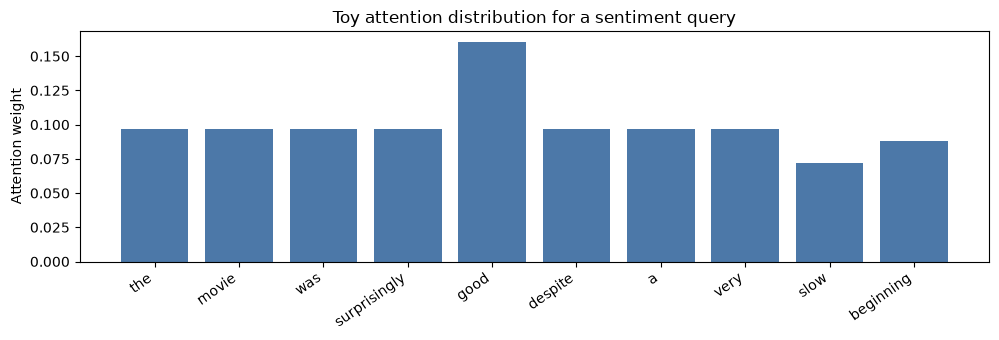

Token có weight cao nhất: good


In [8]:
plt.figure(figsize=(10, 3.5))
plt.bar(tokens, sentiment_weights.ravel(), color='#4c78a8')
plt.ylabel('Attention weight')
plt.xticks(rotation=35, ha='right')
plt.title('Toy attention distribution for a sentiment query')
plt.tight_layout()
plt.show()
print('Token có weight cao nhất:', tokens[int(np.argmax(sentiment_weights))])

**Trả lời:** Với query sentiment và các vector giả lập, token `good` có attention weight lớn nhất là 0.1602. Token `slow` có weight khoảng 0.0720.
Đây chỉ là kết quả từ bộ vector minh họa do mình tự gán, không phải attention mà model đã học từ dữ liệu.

## 19. Experiment 2 — Query thay đổi

In [9]:
_, topic_weights, _ = scaled_dot_product_attention(q_topic, X_toy, X_toy)
query_comparison = pd.DataFrame({'token': tokens, 'sentiment_query': sentiment_weights.ravel(), 'topic_query': topic_weights.ravel()})
query_comparison

,token,sentiment_query,topic_query
0,the,0.097140,0.089135
1,movie,0.097140,0.146959
2,was,0.097140,0.089135
3,surprisingly,0.097140,0.098509
4,good,0.160157,0.098509
5,despite,0.097140,0.080653
6,a,0.097140,0.089135
7,very,0.097140,0.089135
8,slow,0.071963,0.098509
9,beginning,0.087896,0.120320


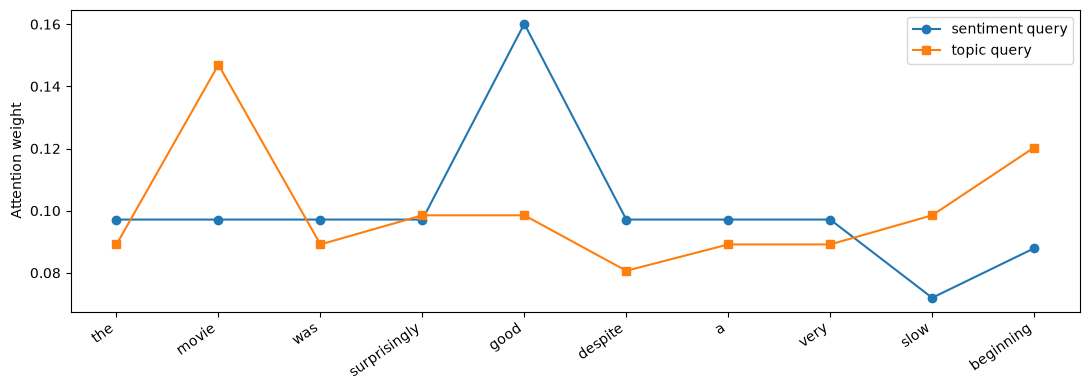

In [10]:
positions = np.arange(len(tokens))
plt.figure(figsize=(11, 4))
plt.plot(positions, sentiment_weights.ravel(), marker='o', label='sentiment query')
plt.plot(positions, topic_weights.ravel(), marker='s', label='topic query')
plt.xticks(positions, tokens, rotation=35, ha='right')
plt.ylabel('Attention weight')
plt.legend()
plt.tight_layout()
plt.show()

**Trả lời:** Khi dùng query sentiment, token `good` có weight cao nhất là 0.1602. Khi đổi sang query topic, token `movie` nhận weight cao nhất khoảng 0.1470.
Như vậy attention distribution thay đổi theo query. Một token có thể quan trọng với query này nhưng không quan trọng nhất với query khác.

## 20. Self-attention

Trong self-attention, `Q`, `K`, `V` được chiếu từ cùng sequence `X` bằng `WQ`, `WK`, `WV`. Mỗi token tạo context bằng cách kết hợp value của các token trong sequence.

## 21. Self-attention — ví dụ minh họa

Đề không cung cấp giá trị số của `X`, `WQ`, `WK`, `WV`. Dùng ví dụ nhỏ dưới đây để quan sát phép tính; đây không phải ma trận được ghi trong đề.

In [11]:
X_example = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)
WQ = WK = WV = np.eye(2)
scores_example, weights_example, context_example, Q_example = self_attention(X_example, WQ, WK, WV)
print('Q = K = V =')
print(X_example)
print('Scaled scores:')
print(np.round(scores_example, 4))
print('Attention weights:')
print(np.round(weights_example, 4))
print('Context:')
print(np.round(context_example, 4))

Q = K = V =
[[1. 0.]
 [0. 1.]
 [1. 1.]]
Scaled scores:
[[0.7071 0.     0.7071]
 [0.     0.7071 0.7071]
 [0.7071 0.7071 1.4142]]
Attention weights:
[[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]
Context:
[[0.8022 0.5989]
 [0.5989 0.8022]
 [0.7517 0.7517]]


## Chuẩn bị dữ liệu IMDb

In [12]:
def tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())

splits = {name: pd.read_csv(DATA_DIR / f'imdb_{name}.csv.gz') for name in ['train', 'validation', 'test']}
dataset_summary = pd.DataFrame([
    {'split': name, 'samples': len(frame), 'negative': int((frame.label == 0).sum()), 'positive': int((frame.label == 1).sum()), 'missing_text': int(frame.text.isna().sum())}
    for name, frame in splits.items()
])
dataset_summary

,split,samples,negative,positive,missing_text
0,train,29749,14819,14930,0
1,validation,9916,4939,4977,0
2,test,9917,4940,4977,0


In [13]:
def balanced_sample(frame, per_class, seed):
    parts = [frame[frame.label == label].sample(n=per_class, random_state=seed) for label in [0, 1]]
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

experiment_splits = {
    'train': balanced_sample(splits['train'], 2000, SEED),
    'validation': balanced_sample(splits['validation'], 500, SEED),
    'test': balanced_sample(splits['test'], 1000, SEED),
}
pd.DataFrame([{'split': name, 'samples': len(frame), 'negative': int((frame.label == 0).sum()), 'positive': int((frame.label == 1).sum())} for name, frame in experiment_splits.items()])

,split,samples,negative,positive
0,train,4000,2000,2000
1,validation,1000,500,500
2,test,2000,1000,1000


## Từ vựng và batches

In [14]:
MAX_LENGTH = 100
VOCAB_LIMIT = 8000
PAD, UNK = 0, 1
counts = Counter(token for text in experiment_splits['train'].text for token in tokenize(text))
vocabulary = {'<pad>': PAD, '<unk>': UNK}
for word, _ in counts.most_common(VOCAB_LIMIT - len(vocabulary)):
    vocabulary[word] = len(vocabulary)

def encode_text(text):
    tokens = tokenize(text)[:MAX_LENGTH]
    ids = [vocabulary.get(token, UNK) for token in tokens]
    mask = [1] * len(ids)
    ids += [PAD] * (MAX_LENGTH - len(ids))
    mask += [0] * (MAX_LENGTH - len(mask))
    return ids, mask, tokens

def make_loader(frame, shuffle=False):
    encoded = [encode_text(text) for text in frame.text]
    ids = torch.tensor([item[0] for item in encoded], dtype=torch.long)
    mask = torch.tensor([item[1] for item in encoded], dtype=torch.bool)
    labels = torch.tensor(frame.label.to_numpy(), dtype=torch.long)
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(TensorDataset(ids, mask, labels), batch_size=64, shuffle=shuffle, generator=generator)

train_loader = make_loader(experiment_splits['train'], shuffle=True)
validation_loader = make_loader(experiment_splits['validation'])
test_loader = make_loader(experiment_splits['test'])
print('vocabulary:', len(vocabulary), '| max_length:', MAX_LENGTH)

vocabulary: 8000 | max_length: 100


## Model definitions

In [15]:
class SelfAttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.query = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.key = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.value = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.classifier = nn.Linear(embedding_dim, 2)

    def forward(self, input_ids, mask):
        embedded = self.embedding(input_ids)
        q, k, v = self.query(embedded), self.key(embedded), self.value(embedded)
        scores = q @ k.transpose(1, 2) / np.sqrt(q.shape[-1])
        scores = scores.masked_fill(~mask[:, None, :], torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores, dim=-1)
        context = weights @ v
        context = context * mask.unsqueeze(-1)
        pooled = context.sum(dim=1) / mask.sum(dim=1, keepdim=True).clamp(min=1)
        return self.classifier(pooled), weights


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32, hidden_dim=32):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, input_ids, mask):
        lengths = mask.sum(dim=1).cpu()
        embedded = self.embedding(input_ids)
        _, (hidden, _) = self.lstm(nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False))
        return self.classifier(hidden[-1]), None


def metric_dict(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
    }


def predict_loader(model, loader):
    model.eval()
    labels, predictions, probabilities = [], [], []
    with torch.no_grad():
        for ids, mask, target in loader:
            logits, _ = model(ids.to(DEVICE), mask.to(DEVICE))
            probs = torch.softmax(logits, dim=1)
            labels.extend(target.numpy().tolist())
            predictions.extend(logits.argmax(dim=1).cpu().numpy().tolist())
            probabilities.extend(probs[:, 1].cpu().numpy().tolist())
    return np.array(labels), np.array(predictions), np.array(probabilities)


def fit_model(model, epochs=5):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    best_f1, best_state = -1.0, None
    start = perf_counter()
    for epoch in range(epochs):
        model.train()
        for ids, mask, target in train_loader:
            ids, mask, target = ids.to(DEVICE), mask.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(ids, mask)
            loss = loss_fn(logits, target)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        val_y, val_pred, _ = predict_loader(model, validation_loader)
        val_metrics = metric_dict(val_y, val_pred)
        if val_metrics['f1'] > best_f1:
            best_f1 = val_metrics['f1']
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        print(f'epoch {epoch + 1}/{epochs}: validation F1={val_metrics["f1"]:.4f}')
    training_time = perf_counter() - start
    model.load_state_dict(best_state)
    return model, training_time

## Huấn luyện và quantitative evaluation

In [16]:
torch.manual_seed(SEED)
lstm_model, lstm_time = fit_model(LSTMClassifier(len(vocabulary)))
torch.manual_seed(SEED)
attention_model, attention_time = fit_model(SelfAttentionClassifier(len(vocabulary)))

model_runs = {}
for name, model, elapsed in [('LSTM', lstm_model, lstm_time), ('Self-Attention', attention_model, attention_time)]:
    y_true, y_pred, y_prob = predict_loader(model, test_loader)
    model_runs[name] = {'model': model, 'y_true': y_true, 'y_pred': y_pred, 'y_prob': y_prob, 'metrics': metric_dict(y_true, y_pred), 'training_time_sec': elapsed}

result_rows = []
for name, run in model_runs.items():
    result_rows.append({
        'model': name,
        'representation': 'final LSTM hidden state' if name == 'LSTM' else 'self-attention + masked mean pooling',
        'parameters': sum(parameter.numel() for parameter in run['model'].parameters()),
        'training_time_sec': round(run['training_time_sec'], 3),
        'epochs': 5,
        'max_length': MAX_LENGTH,
        'vocabulary_size': len(vocabulary),
        'train_samples': len(experiment_splits['train']),
        'validation_samples': len(experiment_splits['validation']),
        'test_samples': len(experiment_splits['test']),
        **{key: round(value, 6) for key, value in run['metrics'].items()},
    })
results_df = pd.DataFrame(result_rows)
results_df.to_csv(LAB_DIR / 'results.csv', index=False)
print('Saved results.csv')

epoch 1/5: validation F1=0.4454


epoch 2/5: validation F1=0.5100


epoch 3/5: validation F1=0.4521


epoch 4/5: validation F1=0.4994


epoch 5/5: validation F1=0.6696


...

epoch 2/5: validation F1=0.6743


epoch 3/5: validation F1=0.7082


epoch 4/5: validation F1=0.7550


epoch 5/5: validation F1=0.7602


Saved results.csv


**Trả lời:** LSTM sử dụng hidden state cuối để biểu diễn review, còn Self-Attention tạo context vector cho từng token rồi lấy trung bình các context ở vị trí không phải padding.

Trong thí nghiệm này, Self-Attention đạt test F1 = 0.7226, cao hơn LSTM với F1 = 0.6548. Training time của Self-Attention là 3.55 giây, thấp hơn LSTM là 21.78 giây.

Tuy nhiên LSTM có recall = 0.7550, cao hơn Self-Attention là 0.7100. Vì vậy Attention không tốt hơn ở mọi metric. Các kết quả chỉ phản ánh lần chạy với cấu hình và dữ liệu hiện tại.

## 22–23. Attention matrix và heatmap

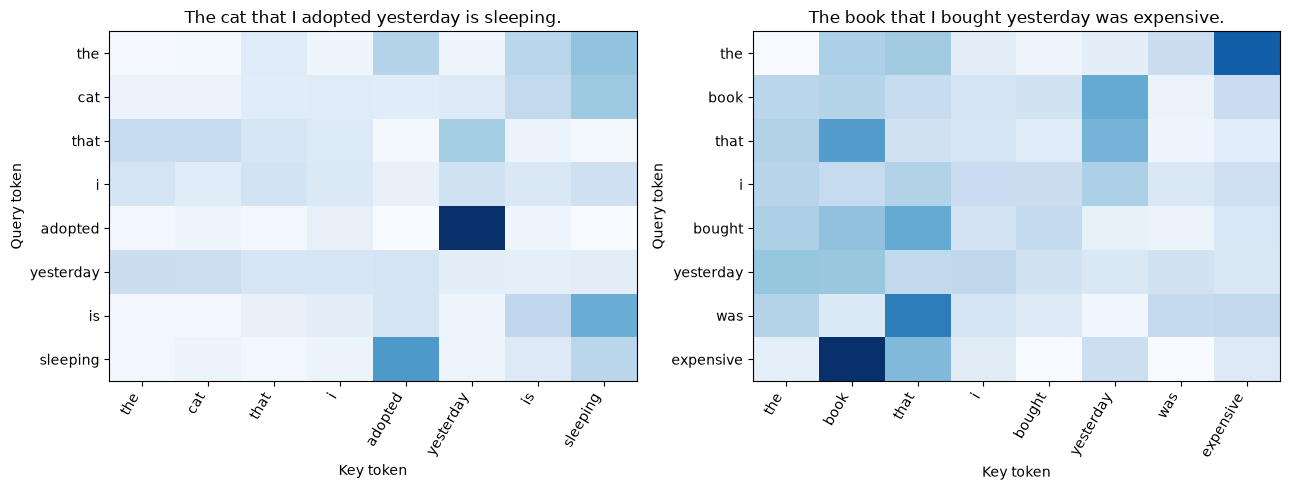

,sentence,query_token,top_attended_tokens,weights
0,The cat that I adopted yesterday is sleeping.,cat,"sleeping, is, yesterday","0.303, 0.213, 0.099"
1,The cat that I adopted yesterday is sleeping.,adopted,"yesterday, i, cat","0.815, 0.064, 0.036"
2,The cat that I adopted yesterday is sleeping.,sleeping,"adopted, sleeping, is","0.482, 0.235, 0.107"


In [17]:
grammar_sentences = [
    'The cat that I adopted yesterday is sleeping.',
    'The book that I bought yesterday was expensive.',
]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grammar_attention = {}
for ax, sentence in zip(axes, grammar_sentences):
    ids, mask, tokens = encode_text(sentence)
    with torch.no_grad():
        _, weights = attention_model(torch.tensor([ids], device=DEVICE), torch.tensor([mask], dtype=torch.bool, device=DEVICE))
    matrix = weights[0, :len(tokens), :len(tokens)].cpu().numpy()
    grammar_attention[sentence] = (tokens, matrix)
    ax.imshow(matrix, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(tokens)), tokens, rotation=60, ha='right')
    ax.set_yticks(range(len(tokens)), tokens)
    ax.set_title(sentence)
    ax.set_xlabel('Key token')
    ax.set_ylabel('Query token')
fig.tight_layout()
fig.savefig(LAB_DIR / 'attention_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

selected_rows = []
for sentence, (tokens, matrix) in grammar_attention.items():
    for target in ['cat', 'adopted', 'sleeping']:
        if target in tokens:
            row = matrix[tokens.index(target)]
            top = np.argsort(row)[::-1][:3]
            selected_rows.append({'sentence': sentence, 'query_token': target, 'top_attended_tokens': ', '.join(tokens[index] for index in top), 'weights': ', '.join(f'{row[index]:.3f}' for index in top)})
pd.DataFrame(selected_rows)

**Quan sát:** Trong attention matrix, mỗi hàng thể hiện một query token đang phân phối attention tới các key token nào.

Ở câu `The cat that I adopted yesterday is sleeping`, token `cat` chú ý nhiều nhất tới `sleeping` với weight = 0.303. Token `adopted` chú ý nhiều nhất tới `yesterday` với weight = 0.815, còn `sleeping` chú ý nhiều nhất tới `adopted` với weight = 0.482.

Các kết quả này cho thấy attention weight khác nhau giữa các token. Tuy nhiên, chỉ dựa trên heatmap thì chưa đủ để kết luận model thực sự hiểu quan hệ ngữ pháp của câu.

## 24. Experiment 4 — LSTM context và attention context

Hai classifier dùng cùng split, giới hạn độ dài và vocabulary. LSTM dùng hidden state cuối; attention model dùng self-attention rồi mean-pooling các context vector không padding.

In [18]:
results_df

,model,representation,parameters,training_time_sec,epochs,max_length,vocabulary_size,train_samples,validation_samples,test_samples,accuracy,precision,recall,f1
0,LSTM,final LSTM hidden state,264514,21.78,5,100,8000,4000,1000,2000,0.6020,0.578101,0.755,0.654814
1,Self-Attention,self-attention + masked mean pooling,259138,3.55,5,100,8000,4000,1000,2000,0.7275,0.735751,0.710,0.722646


## 25. Experiment 5 — Sequence length và computational cost

In [19]:
lengths = [10, 100, 500, 1000, 10000]
cost_table = pd.DataFrame({'sequence_length': lengths, 'matrix_shape': [f'{n} x {n}' for n in lengths], 'matrix_elements': [n * n for n in lengths]})
cost_table

,sequence_length,matrix_shape,matrix_elements
0,10,10 x 10,100
1,100,100 x 100,10000
2,500,500 x 500,250000
3,1000,1000 x 1000,1000000
4,10000,10000 x 10000,100000000


**Trả lời:** Tăng sequence từ 1.000 lên 10.000 token làm số phần tử tăng từ 1 triệu lên 100 triệu. Full self-attention cần lưu và tính score cho các cặp token, nên bộ nhớ và chi phí tăng theo `O(T²)`.

## 26. Application — Context-aware sentiment

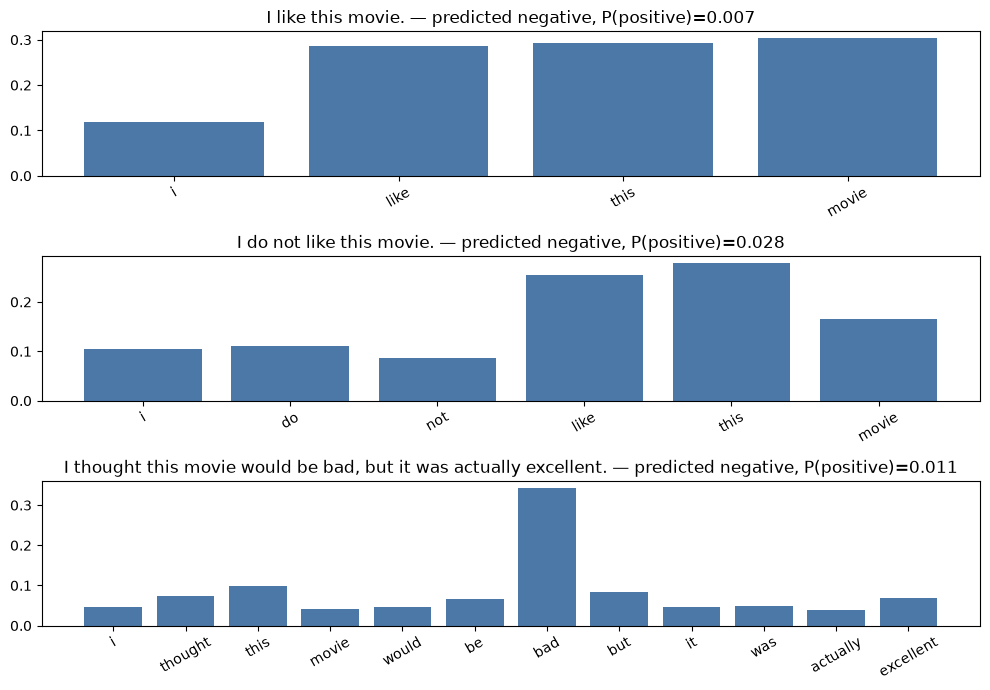

,sentence,expected_label,prediction,P(positive),correct
0,I like this movie.,positive,negative,0.007446,False
1,I do not like this movie.,negative,negative,0.027663,True
2,"I thought this movie would be bad, but it was ...",positive,negative,0.011331,False


In [20]:
application_sentences = [
    'I like this movie.',
    'I do not like this movie.',
    'I thought this movie would be bad, but it was actually excellent.',
]
application_labels = [1, 0, 1]
application_rows = []
application_fig, application_axes = plt.subplots(len(application_sentences), 1, figsize=(10, 7))
for ax, sentence, expected in zip(application_axes, application_sentences, application_labels):
    ids, mask, tokens = encode_text(sentence)
    with torch.no_grad():
        logits, weights = attention_model(torch.tensor([ids], device=DEVICE), torch.tensor([mask], dtype=torch.bool, device=DEVICE))
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
    prediction = int(np.argmax(probabilities))
    application_rows.append({'sentence': sentence, 'expected_label': 'positive' if expected else 'negative', 'prediction': 'positive' if prediction else 'negative', 'P(positive)': probabilities[1], 'correct': prediction == expected})
    token_attention = weights[0, :len(tokens), :len(tokens)].mean(dim=0).cpu().numpy()
    ax.bar(tokens, token_attention, color='#4c78a8')
    ax.set_title(f'{sentence} — predicted {application_rows[-1]["prediction"]}, P(positive)={probabilities[1]:.3f}')
    ax.tick_params(axis='x', rotation=30)
application_table = pd.DataFrame(application_rows)
application_fig.tight_layout()
plt.show()
application_table

**Trả lời:** Trong ba câu thử nghiệm, model chỉ dự đoán đúng câu `I do not like this movie.` với xác suất Positive = 0.0277.

Câu `I like this movie.` bị dự đoán Negative dù kỳ vọng là Positive, với P(positive) = 0.0074.

Câu `I thought this movie would be bad, but it was actually excellent.` cũng bị dự đoán Negative, với P(positive) = 0.0113. Đây là câu có hai vế mang sentiment trái chiều và phần sau có từ `excellent`.

Như vậy, model chưa xử lý tốt hai câu Positive trong ví dụ này, đặc biệt là câu có contrast. Attention visualization có thể dùng để quan sát token nào nhận weight lớn, nhưng chưa đủ để khẳng định nguyên nhân prediction sai.

## Confusion matrix

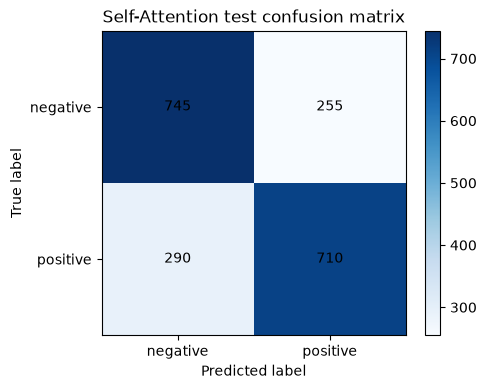

array([[745, 255],
       [290, 710]])

In [21]:
attention_run = model_runs['Self-Attention']
matrix = confusion_matrix(attention_run['y_true'], attention_run['y_pred'], labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(matrix, cmap='Blues')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'], xlabel='Predicted label', ylabel='True label', title='Self-Attention test confusion matrix')
for (row, col), value in np.ndenumerate(matrix):
    ax.text(col, row, str(value), ha='center', va='center')
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(LAB_DIR / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()
matrix

**Nhận xét:** Trên test set, confusion matrix có TN = 745, FP = 255, FN = 290 và TP = 710.

False Negative nhiều hơn False Positive, nghĩa là model bỏ sót review Positive nhiều hơn số review Negative bị dự đoán nhầm thành Positive.

Điều này cũng phù hợp với precision = 0.7358 cao hơn recall = 0.7100.

## 27. Error analysis samples

In [22]:
test_frame = experiment_splits['test'].copy().reset_index(drop=True)
test_frame['prediction'] = attention_run['y_pred']
test_frame['p_positive'] = attention_run['y_prob']
test_frame['correct'] = test_frame.label == test_frame.prediction
selected = pd.concat([test_frame[test_frame.correct].head(3), test_frame[~test_frame.correct].head(3)]).copy()
error_rows = []
for row in selected.itertuples():
    ids, mask, tokens = encode_text(row.text)
    with torch.no_grad():
        _, weights = attention_model(torch.tensor([ids], device=DEVICE), torch.tensor([mask], dtype=torch.bool, device=DEVICE))
    length = len(tokens)
    received = weights[0, :length, :length].mean(dim=0).cpu().numpy()
    top = np.argsort(received)[::-1][:5]
    error_rows.append({
        'text_preview': re.sub(r'\s+', ' ', row.text)[:280],
        'true_label': 'positive' if row.label else 'negative',
        'prediction': 'positive' if row.prediction else 'negative',
        'p_positive': round(row.p_positive, 4),
        'sequence_length': len(tokenize(row.text)),
        'truncated': len(tokenize(row.text)) > MAX_LENGTH,
        'top_attention_tokens': ', '.join(tokens[index] for index in top),
        'correct': row.correct,
    })
error_examples = pd.DataFrame(error_rows)
error_examples

,text_preview,true_label,prediction,p_positive,sequence_length,truncated,top_attention_tokens,correct
0,I am definitely in the minority opinion on thi...,negative,negative,0.0317,159,True,"worst, they, did, year, awards",True
1,Great movie. I was laughing all time through. ...,positive,positive,0.7110,84,False,"why, great, they, which, all",True
2,"Oh, my. Oh, this is a *really* bad movie. The ...",negative,negative,0.0164,274,True,"bad, bad, dead, awful, died",True
3,"I did not intend to write this review, but hav...",positive,negative,0.2537,565,True,"show, read, point, did, off",False
4,"This movie had an interesting cast, it mat not...",positive,negative,0.3784,157,True,"ordinary, job, im, they, they",False
5,"Ed Gein, one of the most famous serial killers...",negative,positive,0.8495,305,True,"few, watched, most, most, all",False


**Ghi chú:** Các weight là kết quả của model. Khi phân tích prediction sai, xem chúng như một dấu hiệu để đối chiếu với câu và nhãn, không dùng riêng heatmap để kết luận nguyên nhân.

## 28. So sánh Lab 05 và Lab 06

Attention giúp tạo tương tác trực tiếp giữa các vị trí trong sequence, kể cả token ở xa. Full self-attention cần tính mọi cặp token và có chi phí `O(T²)`; recurrent model xử lý tuần tự theo timestep.

Classifier Self-Attention hiện tại chưa có thông tin vị trí và dùng mean pooling, nên không phân biệt thứ tự của cùng một nhóm token được giữ lại sau truncation. Đây là một giới hạn khi xử lý phủ định và các câu có nhiều vế.

## 29. Attention không miễn phí

Attention giảm phụ thuộc vào truyền hidden state tuần tự nhưng chi phí full self-attention tăng theo bình phương sequence length. Vì vậy attention không phải lúc nào cũng thay thế recurrent model.

## 30. AI assistance statement

AI hỗ trợ implementation, debugging và biểu diễn kết quả. Các phép tính, prediction và diễn giải trong các file nộp cần được đọc lại và đối chiếu với kết quả notebook.